# Week 1 — Linear Regression
**Module C Capstone · Mo Chung Ting (Miu)**

**What this notebook does, in plain words**

This week is about *checking the data*, not building the best predictor. Two jobs:

1. **Do the Polish ratios repeat each other?** (Steps 1–4)
   Many of the 64 ratios may say the same thing in different ways. We measure this with VIF.
   VIF only looks at the ratios, never at who went bankrupt, so it doesn't matter that bankruptcy is yes/no.
2. **What decides a customer's credit limit?** (Steps 5–8)
   Linear regression needs a number to predict, not a yes/no. The credit limit (`LIMIT_BAL`) is a real
   number set by the bank, so we predict that. This dataset also has real categories (sex, education,
   marriage), which this week asks us to use.

**Week topics → steps:** multicollinearity and VIF (Step 4) · categorical + continuous features (Step 6) ·
polynomial term (Step 7) · interaction term (Step 8).

**Research questions:** RQ2 (do the ratio families overlap?) · RQ4 (behaviour vs personal details).

## Datasets used

- **Polish Companies Bankruptcy** — UCI Machine Learning Repository, DOI [10.24432/C5F600](https://doi.org/10.24432/C5F600).
  Polish firms, 2000–2013. Each row is one firm: 64 financial ratios, and `class` = 1 if it went bankrupt.
  - **File used:** `polish_predict_3y.csv` — 10,503 firms (10,416 after removing duplicates), 4.7% bankrupt.
  File naming: `polish_predict_3y.csv` = ratios used to predict bankruptcy **3 years ahead**
  (UCI's original `3year.arff`; our files are renamed by forecast distance).
  - **Used for:** Steps 1–4 — duplicates, missing values, multicollinearity (VIF). The bankruptcy label is not modelled this week.
- **Default of Credit Card Clients** — UCI, DOI [10.24432/C55S3H](https://doi.org/10.24432/C55S3H).
  30,000 Taiwanese card holders, 2005: credit limit, sex, education, marriage, age, 6 months of repayment
  status, bills and payments.
  - **File used:** `credit_card_default.csv`.
  - **Used for:** Steps 5–8 — linear regression predicting the credit limit, log(`LIMIT_BAL`), plus the VIF yardstick in Step 4.
  - **Not used:** `default payment next month` — it happens after the limit was set.

In [1]:
import numpy as np
import pandas as pd
from pathlib import Path

DATA = Path("../Dataset_new/CSV")
pd.set_option("display.width", 120)

## Step 1 — Load the data and count

**What we do:** open the 5 Polish files and the credit card file, and count rows and bankruptcies.

**Things to know:**
- Each Polish file is named by **how far ahead it predicts**. `polish_predict_5y.csv` = data from 5 years
  before the outcome. (UCI's original name for this file is `1year.arff`, which is confusing — that's why we renamed.)
- The 5 files are kept **separate**. There are no company IDs, so the same company could be in more than
  one file. Mixing them could put one company in both the training and the test data.
- **Base rate** = share of firms that went bankrupt = bankrupt ÷ rows.

In [2]:
polish = {h: pd.read_csv(DATA / f"polish_predict_{h}y.csv") for h in range(1, 6)}
credit = pd.read_csv(DATA / "credit_card_default.csv")

# Polish: 64 ratio columns; 'years_ahead' is a label we added, not a feature
FEATURES = [c for c in polish[1].columns if c not in ("class", "years_ahead")]
print(len(FEATURES), "Polish features")

summary = pd.DataFrame({
    h: {"rows": len(df), "bankrupt": df["class"].sum(), "base_rate": df["class"].mean()}
    for h, df in polish.items()
}).T
summary.index.name = "years_ahead"
summary

64 Polish features


,rows,bankrupt,base_rate
years_ahead,,,
1,5910.0,410.0,0.069374
2,9792.0,515.0,0.052594
3,10503.0,495.0,0.047129
4,10173.0,400.0,0.039320
5,7027.0,271.0,0.038566


**Credit card file:** count rows and columns, and the share of customers who defaulted.
`.mean()` on a 0/1 column = share of 1s. Example: (0 + 1 + 0 + 0) ÷ 4 = 0.25 → 25% defaulted.
`.head(3)` shows the first 3 rows, to check the file loaded correctly.

In [3]:
print(credit.shape)
print("default rate:", round(credit["default payment next month"].mean(), 4))
credit.head(3)

(30000, 25)
default rate: 0.2212


,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default payment next month
0,1,20000,2,2,1,24,2,2,-1,-1,...,0,0,0,0,689,0,0,0,0,1
1,2,120000,2,2,2,26,-1,2,0,0,...,3272,3455,3261,0,1000,1000,1000,0,2000,1
2,3,90000,2,2,2,34,0,0,0,0,...,14331,14948,15549,1518,1500,1000,1000,1000,5000,0


**What we found**
- Bankruptcy gets rarer the further ahead we look: **6.9%** of firms at 1 year ahead, **3.9%** at 5 years ahead.
- The 5-year file has only **271** bankrupt firms — the least data for the hardest question.
- This notebook uses the **3-year file** for VIF: it is the biggest (10,503 firms, 4.7% bankrupt) and sits in the middle.
- Credit card: **30,000** customers, **22.1%** defaulted.
- These rates describe *this dataset*, not all Polish companies.

## Step 2 — Remove duplicate rows

**What we do:** find rows that are exact copies of another row (same values in all 64 ratios), and remove them.

**Why:** if a firm and its copy end up on opposite sides of a train/test split, the model is tested on
something it has already seen. Results would look better than they really are.

We also count **label conflicts**: two identical rows where one went bankrupt and the other didn't.
Zero conflicts means the copies are true duplicates.

In [4]:
dup_report = {}
for h, df in polish.items():
    dup_mask = df.duplicated(subset=FEATURES, keep="first")
    # label conflict = same 64 ratios, different class
    conflicts = df.groupby(FEATURES, dropna=False)["class"].nunique().gt(1).sum()
    dup_report[h] = {"duplicates": dup_mask.sum(), "label_conflicts": conflicts}
pd.DataFrame(dup_report).T

,duplicates,label_conflicts
1,60,0
2,82,0
3,87,0
4,90,0
5,82,0


**Remove the copies, then recount.** `drop_duplicates` keeps the first row of each copied group and
deletes the rest. Then we check how many rows and bankruptcies are left in each file.
We also count copied customers in the credit card file (ignoring `ID`, which is always unique).

In [5]:
polish = {h: df.drop_duplicates(subset=FEATURES).reset_index(drop=True) for h, df in polish.items()}
print("credit card duplicates (excluding ID):",
      credit.drop(columns="ID").duplicated().sum())

pd.DataFrame({h: {"rows": len(df), "bankrupt": df["class"].sum(),
                  "base_rate": round(df["class"].mean(), 4)} for h, df in polish.items()}).T

credit card duplicates (excluding ID): 35


,rows,bankrupt,base_rate
1,5850.0,408.0,0.0697
2,9710.0,513.0,0.0528
3,10416.0,493.0,0.0473
4,10083.0,398.0,0.0395
5,6945.0,271.0,0.0390


**What we found**
- Every Polish file has **60–90 copied rows** (87 in the 3-year file), and **no label conflicts**.
- They can't be coincidence: two different firms matching on 64 detailed ratios is practically impossible.
- After removal, the 3-year file has **10,416 rows** (493 bankrupt, 4.73%). The bankruptcy rate barely changes.
- The credit card file has **35** copied customers; they are removed in Step 5.

## Step 3 — Missing values (Polish 3-year file)

**The problem:** VIF and regression stop with an error if any cell is blank. Every blank must be gone before Step 4.

**Two ways to remove blanks:**
- **Delete the column** → lose that ratio.
- **Delete the row** → lose that firm.

**Plan:** delete the 2 columns with the most blanks, then delete any firm that still has a blank.
Then check: did deleting firms change the bankruptcy rate?

In [6]:
p3 = polish[3]

# Share of missing values in each column, worst first
missing = p3[FEATURES].isna().mean().sort_values(ascending=False)
print("Columns with any missing:", (missing > 0).sum(), "of", len(FEATURES))
print(missing.head(5).round(3))
print("\nComplete rows (all 64 columns):", p3[FEATURES].dropna().shape[0], "of", len(p3))

Columns with any missing: 44 of 64
liq_quick_to_lt_liab         0.452
grow_sales_growth            0.077
lev_interest_coverage        0.068
act_inventory_turnover       0.057
prof_net_profit_inventory    0.056
dtype: float64

Complete rows (all 64 columns): 4835 of 10416


**Delete the 2 worst columns, then the firms with blanks.**
- `VIF_COLS` = the 62 ratios we keep.
- `dropna` deletes any firm with a blank in those 62 columns.
- Last two lines: compare the bankruptcy rate before and after. If it changes, the deleted firms were not random.

In [7]:
# Drop the two columns with the most gaps, then keep only complete rows
DROP = ["liq_quick_to_lt_liab", "grow_sales_growth"]
VIF_COLS = [c for c in FEATURES if c not in DROP]
p3_complete = p3.dropna(subset=VIF_COLS)

print("Complete rows after dropping 2 columns:", len(p3_complete),
      f"({len(p3_complete) / len(p3):.1%})")

# Check: did dropping incomplete rows change who is left?
print("Bankruptcy rate, all rows:     ", round(p3["class"].mean(), 4))
print("Bankruptcy rate, complete rows:", round(p3_complete["class"].mean(), 4))

Complete rows after dropping 2 columns: 8757 (84.1%)
Bankruptcy rate, all rows:      0.0473
Bankruptcy rate, complete rows: 0.0335


**What we found**
- 44 of 64 columns have at least one blank, but most blanks sit in two columns:
  `liq_quick_to_lt_liab` (45% blank) and `grow_sales_growth` (8% blank). Both are deleted.
- After that, **8,757 of 10,416 firms (84%)** have no blanks and are kept.
- **Warning:** the bankruptcy rate drops from **4.73% to 3.35%**. Firms with blanks go bankrupt more often,
  so deleting them removes about **200 of the 493** bankrupt firms.
- **Is that OK here?** Yes, for VIF only. VIF measures how ratios overlap with each other and never looks at bankruptcy.
- **Not OK for models later** (Week 2 onward). There we fill blanks with the column median instead of
  deleting firms, and add a yes/no column saying "this was blank" — because a blank is itself a warning sign.

## Step 4 — Do the ratios repeat each other? (VIF)

**The idea in plain words:** take one ratio. Try to predict it from all the other ratios. If the others
predict it almost perfectly, this ratio adds nothing new — it repeats information already there.

**How VIF turns that into a number:**
- R² = how well the other ratios predict this one (0 = not at all, 1 = perfectly).
- VIF = 1 ÷ (1 − R²).

| R² | VIF | Meaning |
|---|---|---|
| 0 | 1 | completely new information |
| 0.9 | 10 | 90% repeated — the usual "serious" line |
| 0.99 | 100 | almost a copy |
| 1 | infinite | an exact copy |

**Why it matters:** when ratios repeat each other, regression can't tell which one deserves the credit,
so its coefficients jump around. This problem is called **multicollinearity**.

In [8]:
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.tools import add_constant
import warnings

X_vif = add_constant(p3_complete[VIF_COLS])   # VIF needs an intercept column

with warnings.catch_warnings():
    warnings.simplefilter("ignore")           # silences divide-by-zero for perfect pairs
    vif = pd.Series(
        [variance_inflation_factor(X_vif.values, i) for i in range(1, X_vif.shape[1])],
        index=VIF_COLS,
    )

print("VIF > 10:", (vif > 10).sum(), "of", len(vif))
vif.sort_values(ascending=False).head(10)

VIF > 10: 40 of 62


prof_gross_interest_assets    1.000800e+15
prof_ebit_assets              1.000800e+15
prof_gross_profit_assets      1.000800e+15
act_receivables_inv_days      1.518716e+11
act_inventory_days_sales      5.252471e+10
act_receivables_days          2.845319e+10
prof_gross_dep_sales          1.023326e+08
prof_gross_margin_cogs        4.944847e+05
prof_total_costs_sales        4.907690e+05
lev_assets_liab               2.855766e+05
dtype: float64

**Why some VIFs are about 10¹⁵**

These huge numbers mean "infinite". They appear when a column is an exact copy of other columns.

- VIF = 1 ÷ (1 − R²). An exact copy can be predicted perfectly, so R² = 1, and 1 ÷ 0 = infinite.
- Computers round very slightly, so they get R² = 0.999999999999999 instead of 1. That gives 10¹⁵ instead of infinite.

Two causes in this data:
- `prof_ebit_assets`, `prof_gross_interest_assets` and `prof_gross_profit_assets` have different names but **the same numbers** in almost every row.
- `act_receivables_inv_days` is just `act_receivables_days` + `act_inventory_days_sales` added together.

In [9]:
# VIF by financial family. Median, not mean: one 1e15 value would swamp a mean.
vif_table = pd.DataFrame({"vif": vif, "family": [c.split("_")[0] for c in VIF_COLS]})
vif_table["over_10"] = vif_table["vif"] > 10

vif_table.groupby("family").agg(
    n_ratios=("vif", "size"),
    n_over_10=("over_10", "sum"),
    median_vif=("vif", "median"),
).sort_values("median_vif", ascending=False)

,n_ratios,n_over_10,median_vif
family,,,
prof,21,17,361.559140
act,15,8,90.643078
lev,16,11,64.039735
liq,9,4,9.412268
size,1,0,1.576069


**Picture of Step 4's table.** One box per family, showing the spread of VIF values inside it.
- The x-axis is a **log scale**: each step is ×10 (1, 10, 100, 1000…), so values from 1 to 10¹⁵ fit on one chart.
- The **red line** is VIF = 10. Boxes to the right of it = families that mostly repeat each other.
- Candidate figure for the Week 7 document.

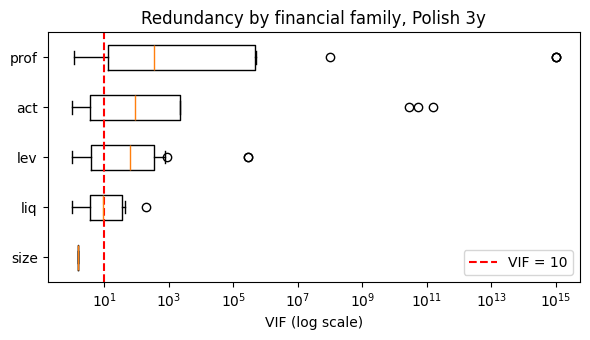

In [10]:
# Figure candidate: VIF distribution per family
import matplotlib.pyplot as plt

order = vif_table.groupby("family")["vif"].median().sort_values().index
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.boxplot([vif_table.loc[vif_table.family == f, "vif"] for f in order],
           tick_labels=order, vert=False)   # matplotlib < 3.9: use labels= instead
ax.set_xscale("log")
ax.axvline(10, color="red", linestyle="--", label="VIF = 10")
ax.set_xlabel("VIF (log scale)")
ax.set_title("Redundancy by financial family, Polish 3y")
ax.legend()
plt.tight_layout()
plt.show()

**A comparison point: VIF for the credit card's six monthly bills.**
`BILL_AMT1`–`BILL_AMT6` are the customer's bill in each of the last six months. One month's bill is close
to the next month's, so we expect them to repeat each other. That makes them a good yardstick:
if even these are "only" around 10–16, then Polish values in the hundreds are severe.

**Result:** VIF 9.7–16.0 — 5 of 6 just above the line of 10. Mild compared with the Polish ratios.

In [11]:
# Baseline for comparison: the six monthly bill amounts in the credit card data
BILL = [f"BILL_AMT{i}" for i in range(1, 7)]
X_bill = add_constant(credit[BILL])
pd.Series([variance_inflation_factor(X_bill.values, i) for i in range(1, 7)],
          index=BILL).round(1)

BILL_AMT1    10.7
BILL_AMT2    16.0
BILL_AMT3    10.8
BILL_AMT4    13.3
BILL_AMT5    15.7
BILL_AMT6     9.7
dtype: float64

**What we found**
- **40 of 62 ratios** have VIF above 10 — most ratios repeat each other.
- **Profitability** repeats the most: 17 of 21 above 10, typical (median) VIF 362. Many profit ratios measure
  the same thing: "is the firm making money compared with its size?"
- **Liquidity** repeats the least: typical VIF 9.4, just under the line.
- For comparison, the credit card's six monthly bills have VIF 9.7–16. The Polish ratios are **far worse**
  (typical VIF 64–362 per family).
- **Careful:** VIF never looks at bankruptcy. "Profitability repeats the most" does **not** mean
  "profitability predicts bankruptcy best". It means lasso (Week 2) will probably keep only one or two profit ratios.

### Step 4b — Remove the exact copies and check again

**Question:** are the 40 high VIFs real, or caused by a few copied columns?

**The copies** (checked in all 5 files, and in the original UCI files):
- `prof_ebit_assets`, `prof_gross_interest_assets`, `prof_gross_profit_assets` → **same numbers** in almost
  every row. Keep the first, delete the other two.
- `act_receivables_inv_days` = `act_receivables_days` + `act_inventory_days_sales` → just the other two
  added up. Delete it, keep the two parts.

That leaves 59 ratios. Then run VIF again.

In [12]:
# Confirm the copies in this sample before dropping
a, b, c = p3_complete["prof_ebit_assets"], p3_complete["prof_gross_profit_assets"], p3_complete["prof_gross_interest_assets"]
print("Attr7 = Attr14 = Attr18 in", ((a == b) & (a == c)).sum(), "of", len(p3_complete), "rows")
gap = p3_complete["act_receivables_inv_days"] - (p3_complete["act_receivables_days"] + p3_complete["act_inventory_days_sales"])
print("Largest |Attr43 − (Attr44 + Attr20)|:", round(gap.abs().max(), 2), "days")

COPIES = ["prof_gross_interest_assets", "prof_gross_profit_assets", "act_receivables_inv_days"]
VIF_COLS_2 = [c for c in VIF_COLS if c not in COPIES]

X_vif2 = add_constant(p3_complete[VIF_COLS_2])
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    vif2 = pd.Series(
        [variance_inflation_factor(X_vif2.values, i) for i in range(1, X_vif2.shape[1])],
        index=VIF_COLS_2,
    )

print("\nVIF > 10:", (vif2 > 10).sum(), "of", len(vif2), " (before:", (vif > 10).sum(), "of", len(vif), ")")
print("VIF > 100:", (vif2 > 100).sum(), " | max VIF:", f"{vif2.max():.3g}")
vif2.sort_values(ascending=False).head(10)

Attr7 = Attr14 = Attr18 in 8756 of 8757 rows
Largest |Attr43 − (Attr44 + Attr20)|: 4.0 days

VIF > 10: 37 of 59  (before: 40 of 62 )
VIF > 100: 21  | max VIF: 4.79e+05


prof_gross_margin_cogs     479004.514647
prof_total_costs_sales     473451.172515
lev_assets_liab            285525.750783
lev_equity_bv_liab         285425.567465
act_curr_liab_days_cogs      2215.252951
act_st_liab_days_cogs        2215.201273
prof_gross_margin            1601.212238
prof_net_margin              1313.247483
lev_net_profit_dep_liab       863.776124
lev_gross_dep_liab            779.396479
dtype: float64

**Same family table as Step 4, after removing the copies.** Compare it with the earlier table:
did the counts above 10 and the typical (median) VIF go down?

In [13]:
# Family view after removing copies
vif_table2 = pd.DataFrame({"vif": vif2, "family": [c.split("_")[0] for c in VIF_COLS_2]})
vif_table2.groupby("family").agg(
    n_ratios=("vif", "size"),
    n_over_10=("vif", lambda v: (v > 10).sum()),
    median_vif=("vif", "median"),
).sort_values("median_vif", ascending=False)

,n_ratios,n_over_10,median_vif
family,,,
prof,19,15,120.966265
lev,16,11,64.027583
act,14,7,15.274615
liq,9,4,9.370178
size,1,0,1.576036


**Figure for the Milestone document (Figure 1).** The same family table as a chart: the share of each family's ratios
with VIF above 10, after removing the copies, labelled with the count and the family's median VIF.

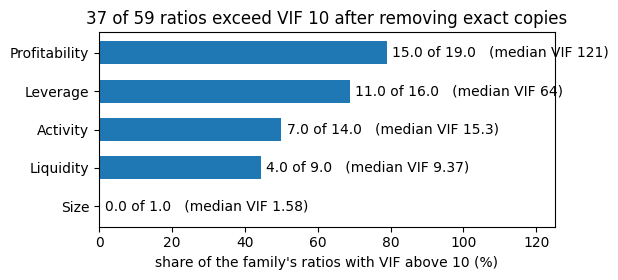

In [14]:
fam2 = vif_table2.groupby("family").agg(n=("vif", "size"), over_10=("vif", lambda v: (v > 10).sum()),
                                        median_vif=("vif", "median"))
fam2 = fam2.sort_values("median_vif")                  # largest overlap at the top of the chart
names = {"prof": "Profitability", "lev": "Leverage", "act": "Activity", "liq": "Liquidity", "size": "Size"}
share = fam2["over_10"] / fam2["n"] * 100

fig, ax = plt.subplots(figsize=(6.2, 2.9))
ax.barh([names[f] for f in fam2.index], share, height=0.6)
for y, (f, row) in enumerate(fam2.iterrows()):
    ax.text(share[f] + 1.5, y, f"{row['over_10']} of {row['n']}   (median VIF {row['median_vif']:.3g})", va="center")
ax.set_xlim(0, 125)
ax.set_xlabel("share of the family's ratios with VIF above 10 (%)")
ax.set_title(f"{fam2['over_10'].sum()} of {fam2['n'].sum()} ratios exceed VIF 10 after removing exact copies")
plt.tight_layout()
plt.show()

**What we found**
- **37 of 59** ratios still have VIF above 10 (was 40 of 62). **21** are above 100.
- The 10¹⁵ values are gone; the largest VIF is now about 480,000.
- So the overlap is **real and widespread**, not caused by a few copied columns.
- The top of the list is now **pairs** of near-copies, e.g. `lev_assets_liab` and `lev_equity_bv_liab`.
  Since assets = debts + equity, one is almost exactly the other plus 1.
- **Conclusion:** ordinary regression on these ratios would be unstable. That's why Weeks 2–3 (lasso, PCR)
  are needed, not optional.

## Step 5 — Credit card: set up the regression

**What we predict:** the customer's credit limit (`LIMIT_BAL`), set by the bank.

**Why log(limit)?** Most limits are modest (half are under 140,000), but a few reach 1,000,000. Those few
would dominate a straight-line fit. The log shrinks big values, and it lets us read coefficients as
**percentage** changes.

**Question:** does the bank set limits from **behaviour** (payments, bills) or **personal details**
(sex, education, marriage)?

**Preparation:**
- Remove the 35 copied customers.
- Merge unknown codes into "other": EDUCATION 0/5/6 → 4, MARRIAGE 0 → 3. (The data guide doesn't explain these codes.)
- **Don't use** `default payment next month` — it happens *after* the limit was set, so it can't explain it.
- **Categories → 0/1 columns ("dummies").** Example: `SEX_2` = 1 if female, 0 if male. One group per
  variable is left out as the comparison group (male · graduate school · married). Keeping all of them
  would create an exact copy — the same infinite-VIF problem as Step 4.

**How we score:** split customers 80% train / 20% test. Fit on train, measure R² on both.
R² = share of the differences in limits the model explains (0 = nothing, 1 = everything).
If train R² is much higher than test R², the model is memorising (**overfitting**).

In [15]:
cc = credit.drop_duplicates(subset=[c for c in credit.columns if c != "ID"]).reset_index(drop=True)
print("Rows after dropping duplicates:", len(cc))

cc["log_limit"] = np.log(cc["LIMIT_BAL"])
cc["EDUCATION"] = cc["EDUCATION"].replace({0: 4, 5: 4, 6: 4})
cc["MARRIAGE"] = cc["MARRIAGE"].replace({0: 3})

# Categorical → one-hot dummy columns. drop_first avoids the "dummy trap"
# (a full set of dummies is perfectly collinear with the intercept, which is infinite VIF again)
dummies = pd.get_dummies(cc[["SEX", "EDUCATION", "MARRIAGE"]].astype(str),
                         prefix=["SEX", "EDU", "MAR"], drop_first=True, dtype=int)
cc = pd.concat([cc, dummies], axis=1)

# Extra terms for Steps 7–8, built now so there is only one train/test split
cc["AGE_sq"] = cc["AGE"] ** 2
cc["AGE_x_grad"] = cc["AGE"] * (cc["EDUCATION"] == 1)   # EDUCATION 1 = graduate school

PAY    = ["PAY_0"] + [f"PAY_{i}" for i in range(2, 7)]
PAYAMT = [f"PAY_AMT{i}" for i in range(1, 7)]
CONT   = ["AGE"] + PAY + BILL + PAYAMT
CAT    = list(dummies.columns)
print("Continuous:", len(CONT), "| Dummies:", CAT)

Rows after dropping duplicates: 29965
Continuous: 19 | Dummies: ['SEX_2', 'EDU_2', 'EDU_3', 'EDU_4', 'MAR_2', 'MAR_3']


**Split the data and write a scoring helper.**
- `train_test_split(..., test_size=0.2)` → 80% of customers to fit the model, 20% kept aside to test it.
  `random_state=42` makes the split the same every run.
- `fit_and_score(cols, label)` fits a linear regression on the chosen columns and returns train R²,
  test R², and the **gap** (train − test). A big gap = overfitting.
- `results` collects one row per model so Steps 6–8 can be compared in one table.

In [16]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score

train, test = train_test_split(cc, test_size=0.2, random_state=42)

def fit_and_score(cols, label):
    """Fit on train, score R² on both train and test, return one row of results."""
    model = LinearRegression().fit(train[cols], train["log_limit"])
    r2_train = r2_score(train["log_limit"], model.predict(train[cols]))
    r2_test  = r2_score(test["log_limit"],  model.predict(test[cols]))
    return {"model": label, "n_features": len(cols),
            "train_R2": round(r2_train, 4), "test_R2": round(r2_test, 4),
            "gap": round(r2_train - r2_test, 4)}

results = []

## Step 6 — Do personal details add anything?

**What we do:** fit two models and compare test R²:
1. age + behaviour (payment status, bills, payments) — 19 columns
2. the same + sex, education, marriage — 25 columns

In [17]:
results.append(fit_and_score(CONT, "1. continuous only"))
results.append(fit_and_score(CONT + CAT, "2. + categoricals"))
pd.DataFrame(results)

,model,n_features,train_R2,test_R2,gap
0,1. continuous only,19,0.3239,0.3187,0.0052
1,2. + categoricals,25,0.3766,0.3688,0.0078


**What we found**
- Age + behaviour explains **31.9%** of the differences in limits (test R²).
- Adding personal details raises it to **36.9%** — **+5 points**.
- Train and test R² are almost equal (gap under 0.01), so **no overfitting**.
- Effects from model 2 (everything else held equal):
  - Female: about **15% higher** limit than male.
  - University: about **31% lower** than graduate school · high school: about **43% lower**.
  - Single: about **13% lower** than married.
- So the bank uses both, but age + behaviour explains much more.

## Step 7 — Polynomial term: AGE²

**Idea:** a straight line says every extra year of age changes the limit by the same amount, forever.
More realistic: limits rise with age, then level off or fall. A straight line can't bend.
Adding **AGE²** (age × age) lets the line curve.

**How to read it:** a **negative** AGE² coefficient means the curve bends down — limits rise, peak, then fall.

In [18]:
results.append(fit_and_score(CONT + CAT + ["AGE_sq"], "3. + AGE²"))
pd.DataFrame(results)

,model,n_features,train_R2,test_R2,gap
0,1. continuous only,19,0.3239,0.3187,0.0052
1,2. + categoricals,25,0.3766,0.3688,0.0078
2,3. + AGE²,26,0.3991,0.3917,0.0074


In [19]:
# Model 3's own age coefficients. Peak age = −b(AGE) ÷ (2 × b(AGE²)), where the curve's slope is zero.
M3 = CONT + CAT + ["AGE_sq"]
m3 = LinearRegression().fit(train[M3], train["log_limit"])
b3 = pd.Series(m3.coef_, index=M3)
print("Peak age:", round(-b3["AGE"] / (2 * b3["AGE_sq"]), 1))
b3[["AGE", "AGE_sq"]].round(4)

Peak age: 43.1


AGE       0.1208
AGE_sq   -0.0014
dtype: float64

**What we found**
- Test R² rises from **36.9% to 39.2%** (+2.3 points) from just one extra column.
- Gap still under 0.01 → no overfitting.
- The AGE² coefficient is **negative** (−0.0014, cell above), so the curve does bend: limits rise with age,
  then fall. The top of the curve is at about **age 43**: −b(AGE) ÷ (2 × b(AGE²)) = 0.121 ÷ 0.0028 ≈ 43.

## Step 8 — Interaction: AGE × graduate

**Idea:** maybe age matters **differently** for different people. Graduates' incomes often keep rising
longer, so each extra year might earn a graduate more credit than a non-graduate.

**How:** a new column `AGE_x_grad` = age if graduate school, 0 otherwise. Its coefficient is the
**extra** effect of each year of age for graduates.

In [20]:
FINAL = CONT + CAT + ["AGE_sq", "AGE_x_grad"]
results.append(fit_and_score(FINAL, "4. + AGE × graduate"))
summary_table = pd.DataFrame(results)
summary_table

,model,n_features,train_R2,test_R2,gap
0,1. continuous only,19,0.3239,0.3187,0.0052
1,2. + categoricals,25,0.3766,0.3688,0.0078
2,3. + AGE²,26,0.3991,0.3917,0.0074
3,4. + AGE × graduate,27,0.4025,0.3964,0.0061


**Look inside the final model.** Each coefficient says how much log(limit) changes when that column
goes up by 1, with everything else held the same.
To turn coefficient b into a % change in the limit: (e^b − 1) × 100.
Example: `SEX_2` = 0.156 → (e^0.156 − 1) × 100 ≈ **17% higher** for women than men.

In [21]:
# Coefficients. Target is a log, so a coefficient b means roughly (e^b − 1) × 100% change in limit.
final_model = LinearRegression().fit(train[FINAL], train["log_limit"])
coefs = pd.Series(final_model.coef_, index=FINAL)
coefs[CAT + ["AGE", "AGE_sq", "AGE_x_grad"]].round(4)

SEX_2         0.1559
EDU_2         0.1075
EDU_3        -0.0427
EDU_4         0.1873
MAR_2        -0.0562
MAR_3        -0.3688
AGE           0.1174
AGE_sq       -0.0014
AGE_x_grad    0.0134
dtype: float64

**What we found**
- Test R² rises from **39.2% to 39.6%** (+0.5 points) — small; gap still under 0.01.
- The interaction coefficient is **positive** (+0.013): each extra year of age adds about 1.3% more credit
  for graduates than for others.
- The single peak of **age 43** from Step 7 splits in two: about **age 42** for non-graduates and about
  **age 47** for graduates. Graduates' limits keep rising about 5 years longer.
- **Turning a coefficient b into %:** (e^b − 1) × 100. Example: SEX_2 = 0.156 → (e^0.156 − 1) × 100 ≈ 17% higher.
- **Careful with the education rows above:** once the interaction is added, EDU_2/3/4 compare groups at
  age 0, which nobody is. Use Step 6's numbers for education effects.

## Expected vs unexpected

The expectations come from the **capstone proposal**, written before this notebook was run.

**Expected**
- Heavy overlap between ratios (31 pairs with r > 0.99) → 40 of 62 ratios have VIF > 10; still 37 of 59 after
  removing copies → **confirmed**.
- `Attr7` and `Attr14` are the same accounting quantity → true, and a third ratio (`Attr18`) is identical too,
  plus one ratio is the sum of two others → **confirmed, but bigger than thought**.
- Credit card bills are the *mildest* overlap of the three datasets (VIF 9.7–16) → typical Polish family VIFs are
  64–362 → **confirmed**.
- Dropping the two worst columns keeps 84–90% of firms → 84.1% kept → **confirmed**.

**Unexpected**
- Firms with blanks go bankrupt far more often: deleting them cut the rate from 4.73% to 3.35%. Blanks are a
  warning sign, not just a nuisance.
- Behaviour and personal details explain only about 40% of credit limits. Most of what sets a limit is not in this data.
- Limits peak around age 43, and about 5 years later for graduates.

## Conclusions

1. **The Polish ratios repeat each other a lot.** 40 of 62 have VIF > 10; still 37 of 59 after removing
   exact copies. Profitability repeats the most (median VIF 121 after cleanup), liquidity the least (9.4).
   **Yardstick:** the credit card's six monthly bills — columns we *expect* to overlap, since this month's
   bill is close to last month's — only reach VIF 9.7–16. Even after cleanup, the typical Polish profitability ratio sits at 121 and leverage at 64 — far worse.
   → Ordinary regression on these ratios is unstable. Weeks 2–3 (lasso, PCR) are needed.
2. **Some columns are copies under different names.** Three profitability ratios hold the same numbers;
   one activity ratio is the sum of two others. Readable names hid this.
3. **Blank cells are a warning sign.** Deleting firms with blanks cut the bankruptcy rate from 4.73% to
   3.35% (about 200 of 493 bankrupt firms lost). Fine for VIF; later weeks must fill blanks instead.
4. **Credit limits:** the final model explains **39.6%** of the differences in limits (test R²).
   Age + behaviour: 31.9% · personal details: +5.0 points · AGE²: +2.3 · interaction: +0.5.
5. **Overfitting:** the train–test gap stayed under 0.01 in all four models. With about 24,000 training
   customers and at most 27 columns, there is little room to memorise.

6. **For the research questions and next weeks.**
   - RQ2: profitability ratios mostly repeat one signal; liquidity ratios carry separate signals. After removing
     one summed column, activity ratios drop from a median VIF of 91 to 15, so most of their overlap came from
     that one column.
   - Week 2 will start from the 59 cleaned ratios, fill blanks with the median plus a yes/no "was blank" column,
     and use lasso and ridge to deal with the overlap.